In [ ]:
import pandas as pd

# Run from the notebooks/ folder. The full dataset is not published (customer PII);
# see data/README.md. A small anonymised sample is in data/sample/.
file_path = '../data/Tima_clean.csv'
df = pd.read_csv(file_path)
df.head()

current_date (mốc tham chiếu, lấy từ max CheckTime): 2019-03-27 15:58:00

Phân bổ BadDebt:
BadDebt
0    2121
1     262
Name: count, dtype: int64
Tỷ lệ nợ xấu: 10.99%

Train: (1906, 11) | Test: (477, 11)

=================== RANDOM FOREST CLASSIFIER ===================
              precision    recall  f1-score   support

           0       0.89      0.91      0.90       425
           1       0.11      0.10      0.10        52

    accuracy                           0.82       477
   macro avg       0.50      0.50      0.50       477
weighted avg       0.81      0.82      0.81       477

Confusion Matrix:
 [[385  40]
 [ 47   5]]
ROC-AUC: 0.6437

=================== RANDOM FOREST REGRESSOR ===================
              precision    recall  f1-score   support

           0       0.93      0.53      0.67       425
           1       0.15      0.65      0.24        52

    accuracy                           0.54       477
   macro avg       0.54      0.59      0.46       477
weighted 

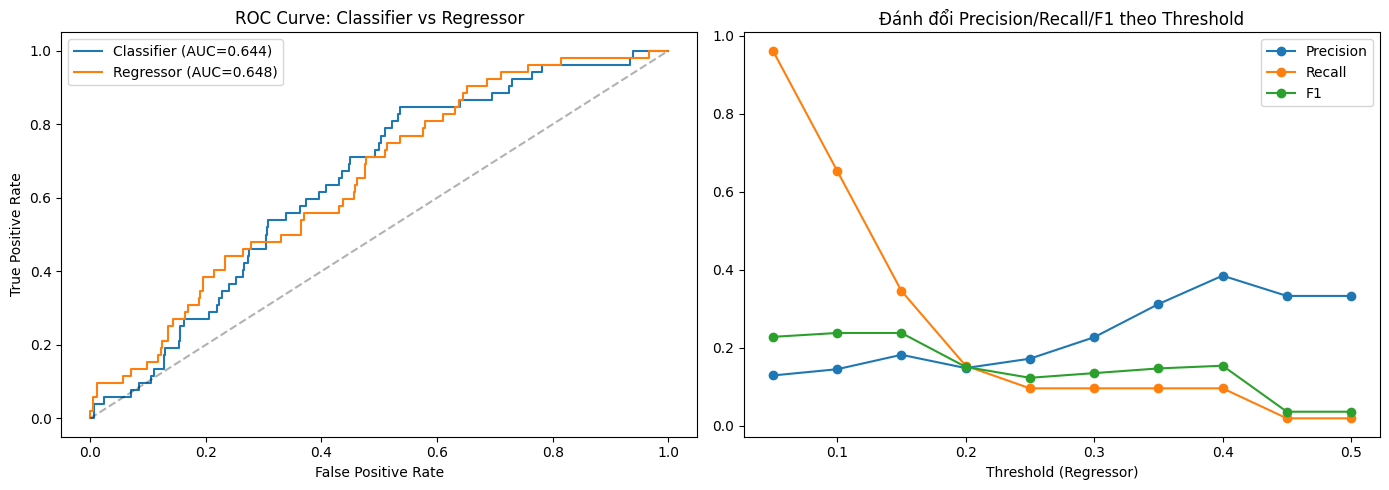

In [8]:
import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import (
    classification_report, confusion_matrix, roc_auc_score, roc_curve
)
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)

# ============================================================================
# 2) CHUẨN HÓA KIỂU DỮ LIỆU SỐ (dùng đúng tên cột tiếng Việt trong file)
# ============================================================================
numeric_cols = [
    "Salary", "Số tiền đăng ký vay ban đầu", "Tiền gốc còn lại", "Tiền giải ngân",
    "TS_CREDIT_SCORE_V2", "NumberOfLoans",
]
for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

df["Salary"] = df["Salary"].fillna(df["Salary"].median())
df["Số tiền đăng ký vay ban đầu"] = df["Số tiền đăng ký vay ban đầu"].fillna(0)
df["Tiền gốc còn lại"] = df["Tiền gốc còn lại"].fillna(0)
df["Tiền giải ngân"] = df["Tiền giải ngân"].fillna(0)
df["HasBadDebt"] = df["HasBadDebt"].fillna(0)
df["HasLatePayment"] = df["HasLatePayment"].fillna(0)

# ============================================================================
# 3) NGÀY THÁNG — dùng mốc thời gian THẬT của dữ liệu, không dùng ngày hệ thống
#    (CheckTime nằm trong khoảng 21/01/2019 - 27/03/2019)
# ============================================================================
df["CheckTime_dt"] = pd.to_datetime(df["CheckTime"], errors="coerce", format="mixed")
current_date = df["CheckTime_dt"].max()
print(f"current_date (mốc tham chiếu, lấy từ max CheckTime): {current_date}")

df["Birthday_dt"] = pd.to_datetime(df["Birthday"], errors="coerce")
df["ToDate_dt"] = pd.to_datetime(df["ToDate"], errors="coerce")
df["FromDate_dt"] = pd.to_datetime(df["FromDate"], errors="coerce")

df["Age"] = (current_date - df["Birthday_dt"]).dt.days // 365
df["Age"] = df["Age"].fillna(df["Age"].median())

df["Loan_Days_Remaining"] = (df["ToDate_dt"] - current_date).dt.days.fillna(0)
df["Loan_Duration_Days"] = (df["ToDate_dt"] - df["FromDate_dt"]).dt.days.fillna(1)

# ============================================================================
# 4) CÁC TỶ LỆ
# ============================================================================
df["Ratio_Remaining_Initial"] = np.where(
    df["Số tiền đăng ký vay ban đầu"] > 0,
    df["Tiền gốc còn lại"] / df["Số tiền đăng ký vay ban đầu"], 0,
)
df["Ratio_Salary_Loan"] = np.where(
    df["Số tiền đăng ký vay ban đầu"] > 0,
    df["Salary"] / df["Số tiền đăng ký vay ban đầu"], 0,
)

# ============================================================================
# 5) TARGET: BadDebt
# ============================================================================
df["BadDebt"] = df["HasBadDebt"].astype(int)
print(f"\nPhân bổ BadDebt:\n{df['BadDebt'].value_counts()}")
print(f"Tỷ lệ nợ xấu: {df['BadDebt'].mean()*100:.2f}%")

# ============================================================================
# 6) LABEL ENCODING CÁC CỘT PHÂN LOẠI
# ============================================================================
categorical_cols = ["Gender", "CityName", "DistrictName", "Hình thức cư trú", "JobName", "ProductCreditName"]
for col in categorical_cols:
    df[col] = LabelEncoder().fit_transform(df[col].astype(str))

feature_cols = [
    "Salary", "Số tiền đăng ký vay ban đầu", "Tiền giải ngân", "TS_CREDIT_SCORE_V2",
    "Age", "Loan_Days_Remaining", "Loan_Duration_Days",
    "Ratio_Remaining_Initial", "Ratio_Salary_Loan", "Gender", "CityName",
]
missing = [c for c in feature_cols if c not in df.columns]
assert not missing, f"Thiếu cột feature: {missing}"

X = df[feature_cols].copy()
y = df["BadDebt"].astype(int).copy()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nTrain: {X_train.shape} | Test: {X_test.shape}")

# ============================================================================
# MÔ HÌNH 1: RandomForestClassifier
# ============================================================================
clf = RandomForestClassifier(
    n_estimators=200, max_depth=10, class_weight="balanced", random_state=42, n_jobs=-1
)
THRESHOLD_CLF = 0.1
clf.fit(X_train, y_train)
y_proba_clf = clf.predict_proba(X_test)[:, 1]
y_pred_clf = clf.predict(X_test)


print("\n=================== RANDOM FOREST CLASSIFIER ===================")
print(classification_report(y_test, y_pred_clf, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_clf))
auc_clf = roc_auc_score(y_test, y_proba_clf)
print(f"ROC-AUC: {auc_clf:.4f}")

# ============================================================================
# MÔ HÌNH 2: RandomForestRegressor (dự báo điểm rủi ro liên tục 0-1)
# ============================================================================
reg = RandomForestRegressor(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1)
reg.fit(X_train, y_train)
y_score_reg = reg.predict(X_test)
y_pred_reg = (y_score_reg >= 0.1).astype(int)

print("\n=================== RANDOM FOREST REGRESSOR ===================")
print(classification_report(y_test, y_pred_reg, zero_division=0))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred_reg))
auc_reg = roc_auc_score(y_test, y_score_reg)
print(f"ROC-AUC: {auc_reg:.4f}")

# ============================================================================
# SO SÁNH 2 MÔ HÌNH
# ============================================================================
report_clf = classification_report(y_test, y_pred_clf, output_dict=True, zero_division=0)
report_reg = classification_report(y_test, y_pred_reg, output_dict=True, zero_division=0)

compare_df = pd.DataFrame({
    "Chỉ số": ["Accuracy", "Precision (lớp 1)", "Recall (lớp 1)", "F1-score (lớp 1)", "ROC-AUC"],
    "RandomForestClassifier": [
        round(report_clf["accuracy"], 4), round(report_clf["1"]["precision"], 4),
        round(report_clf["1"]["recall"], 4), round(report_clf["1"]["f1-score"], 4), round(auc_clf, 4),
    ],
    "RandomForestRegressor (thr=0.1)": [
        round(report_reg["accuracy"], 4), round(report_reg["1"]["precision"], 4),
        round(report_reg["1"]["recall"], 4), round(report_reg["1"]["f1-score"], 4), round(auc_reg, 4),
    ],
})
print("\n=================== BẢNG SO SÁNH ===================")
print(compare_df.to_string(index=False))

agreement = (y_pred_clf == y_pred_reg).mean()
corr = np.corrcoef(y_proba_clf, y_score_reg)[0, 1]
print(f"\nTỷ lệ 2 mô hình dự đoán trùng nhau: {agreement*100:.2f}%")
print(f"Tương quan điểm số Classifier vs Regressor: {corr:.4f}")

# ============================================================================
# FEATURE IMPORTANCE — so sánh 2 mô hình
# ============================================================================
importance_df = pd.DataFrame({
    "Biến": feature_cols,
    "Classifier": clf.feature_importances_,
    "Regressor": reg.feature_importances_,
}).sort_values("Classifier", ascending=False)
print("\n=================== FEATURE IMPORTANCE ===================")
print(importance_df.round(4).to_string(index=False))

# ============================================================================
# QUÉT THRESHOLD CHO REGRESSOR — tìm điểm cân bằng Precision/Recall tốt hơn
# ============================================================================
print("\n=================== QUÉT THRESHOLD CHO REGRESSOR ===================")
threshold_rows = []
for thr in np.arange(0.05, 0.55, 0.05):
    pred_t = (y_score_reg >= thr).astype(int)
    rep_t = classification_report(y_test, pred_t, output_dict=True, zero_division=0)
    p = rep_t.get("1", {}).get("precision", 0)
    r = rep_t.get("1", {}).get("recall", 0)
    f1 = rep_t.get("1", {}).get("f1-score", 0)
    threshold_rows.append({"threshold": round(thr, 2), "precision": round(p, 3), "recall": round(r, 3), "f1": round(f1, 3)})
    print(f"threshold={thr:.2f} | Precision={p:.3f} | Recall={r:.3f} | F1={f1:.3f}")

threshold_df = pd.DataFrame(threshold_rows)
best_thr = threshold_df.loc[threshold_df["f1"].idxmax()]
print(f"\n-> Threshold cho F1 tốt nhất: {best_thr['threshold']} (Precision={best_thr['precision']}, Recall={best_thr['recall']}, F1={best_thr['f1']})")

# ============================================================================
# TRỰC QUAN HÓA
# ============================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

fpr_clf, tpr_clf, _ = roc_curve(y_test, y_proba_clf)
fpr_reg, tpr_reg, _ = roc_curve(y_test, y_score_reg)
axes[0].plot(fpr_clf, tpr_clf, label=f"Classifier (AUC={auc_clf:.3f})")
axes[0].plot(fpr_reg, tpr_reg, label=f"Regressor (AUC={auc_reg:.3f})")
axes[0].plot([0, 1], [0, 1], "k--", alpha=0.3)
axes[0].set_xlabel("False Positive Rate")
axes[0].set_ylabel("True Positive Rate")
axes[0].set_title("ROC Curve: Classifier vs Regressor")
axes[0].legend()

axes[1].plot(threshold_df["threshold"], threshold_df["precision"], marker="o", label="Precision")
axes[1].plot(threshold_df["threshold"], threshold_df["recall"], marker="o", label="Recall")
axes[1].plot(threshold_df["threshold"], threshold_df["f1"], marker="o", label="F1")
axes[1].set_xlabel("Threshold (Regressor)")
axes[1].set_title("Đánh đổi Precision/Recall/F1 theo Threshold")
axes[1].legend()

plt.tight_layout()
plt.show()